# Backtest de los planes: riqueza y UVR

Lee `results/backtest_<plan>.csv` (generados con `python -m uvr_loan.backtest`) y `results/stress_summary.csv` (generado con `python -m uvr_loan.stress`), y muestra estos gráficos, cada uno en su propia celda:

- **Riqueza:** millones de COP de cada plan (planes 1 a 4).
- **Liquidez:** FIC + ETF de cada plan al cierre de cada mes (después del pago y, en los meses de revisión, después de repartir), junto con el pago del mes en COP. Un panel por plan, cada uno con su escala. Las X marcan los meses con déficit.
- **UVR:** UVR real y la UVR proyectada en cada revisión **por el plan 1**. Es la que usa su regla para dimensionar el FIC (el plan 2 decide con su propio LP en UVR): parte de la UVR del día de la revisión y crece con la inflación del escenario `fic_sizing_scenario` calculada en esa revisión (inflación de los últimos `base_lookback_months` meses más el choque) durante los `review_every_months` meses siguientes.
- **Composición:** dinero de cada plan en cada instrumento, en COP y en porcentaje.
- **Prueba de estrés:** riqueza neta final de los planes 2, 3 y 4 cuando cambian solo los precios de los ETF.

Se usan gráficos separados en lugar de varios ejes Y en un mismo gráfico, porque las escalas y unidades son distintas (COP y COP por UVR).

Por defecto muestra `results/`. Para mostrar una corrida de `python -m uvr_loan.forecast_runs [escenario]` define `UVR_CASE` (`trailing`, `median` o `p995`) y, opcionalmente, `UVR_DECISION` (`base`, `high` o `low`) antes de abrir o ejecutar el cuaderno. La prueba de estrés no se recalcula para esas corridas (empiezan en may-2016, no en oct-2016).

In [1]:
import logging
import os

import matplotlib.pyplot as plt
import pandas as pd

from uvr_loan.cashflows import decision_months, month_to_period
from uvr_loan.config import RESULTS_DIR, load_assumptions
from uvr_loan.data.cleaning import load_monthly_panel, to_month_end
from uvr_loan.data.sources import load_raw
from uvr_loan.forecast_runs import T0, case_cfg, output_dir, pad_uvr_history
from uvr_loan.inflation import project_uvr, scenarios

# The data checks of the FIC index are reported by `python -m uvr_loan.data.cleaning`.
logging.getLogger("uvr_loan.data.cleaning").setLevel(logging.ERROR)

cfg = load_assumptions()
# Default: results/ (python -m uvr_loan.backtest). With UVR_CASE (trailing, median, p995) and optionally
# UVR_DECISION (base, high, low) it shows a run of python -m uvr_loan.forecast_runs.
CASE, DECISION = os.environ.get("UVR_CASE"), os.environ.get("UVR_DECISION")
results_dir = RESULTS_DIR
if CASE:
    cfg = case_cfg(cfg, CASE, T0, DECISION)
    results_dir = output_dir(DECISION) / CASE
bt = cfg["backtest"]
k = bt["review_every_months"]
scenario = cfg["conservative"]["fic_sizing_scenario"]
panel = load_monthly_panel(cfg)  # UVR history before each review
if CASE:  # the first reviews need more UVR history than the panel has
    panel = pad_uvr_history(panel, to_month_end(load_raw(cfg)["uvr_cop"]))

PLANS = {
    "conservative": "Plan 1 – conservador",
    "cdt_ladder": "Plan 2 – escalera de CDT",
    "ldi": "Plan 3 – LDI (CDT + ETF)",
    "trend_ldi": "Plan 4 – LDI con filtro de tendencia",
}
results = {}
for plan in PLANS:
    df = pd.read_csv(results_dir / f"backtest_{plan}.csv")
    df["date"] = pd.PeriodIndex(df["period"], freq="M").to_timestamp(how="end").normalize()
    results[plan] = df
dates = results["conservative"]["date"]
results["cdt_ladder"].head()

,month,period,uvr_cop,payment_cop,shortfall_cop,etf_sold_cop,fic_cop,cdt_cop,etf_cop,icolcap_cop,cspx_cop,wealth_cop,is_review,floor_cop,funding_ratio_total,wealth_net_cop,date
0,0,2016-05,239.1436,0.0,0.0,0.0,223.283577,7.599998e+08,0.0,0.0,0.0,7.600000e+08,True,NaN,NaN,7.600000e+08,2016-05-31
1,1,2016-06,240.3319,0.0,0.0,0.0,224.554067,7.648488e+08,0.0,0.0,0.0,7.648490e+08,False,NaN,NaN,7.648490e+08,2016-06-30
2,2,2016-07,241.5402,0.0,0.0,0.0,225.899545,7.697289e+08,0.0,0.0,0.0,7.697291e+08,False,NaN,NaN,7.697291e+08,2016-07-31
3,3,2016-08,242.7495,0.0,0.0,0.0,227.204252,7.746402e+08,0.0,0.0,0.0,7.746405e+08,False,NaN,NaN,7.746405e+08,2016-08-31
4,4,2016-09,242.9697,0.0,0.0,0.0,228.778437,7.795831e+08,0.0,0.0,0.0,7.795833e+08,False,NaN,NaN,7.795833e+08,2016-09-30


## UVR proyectada en cada revisión (plan 1)

Un tramo por revisión τ: los meses τ … τ + k, empezando en la UVR real de τ.

In [2]:
uvr_real = results["conservative"].set_index("month")["uvr_cop"]


def projection(tau: int) -> pd.Series:
    months = range(tau, tau + k + 1)
    inflation = scenarios(cfg, panel.loc[: month_to_period(bt["t0"], tau), "uvr_cop"])[scenario]
    values = [uvr_real[tau], *project_uvr(uvr_real[tau], inflation, k)]
    dates = [month_to_period(bt["t0"], m).to_timestamp(how="end").normalize() for m in months]
    return pd.Series(values, index=dates)


projections = [projection(tau) for tau in decision_months(bt)]

## Gráfico

In [3]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Colorblind-safe palettes: Okabe-Ito for the plans, Paul Tol "muted" for the instruments
# Plan 4: #CC79A7 (next Okabe-Ito hue) is too close to plan 3 under deuteranopia and has contrast < 3:1;
# #942C18 keeps a CVD distance >= 16 (OKLab x100) from the other three and contrast 7.8:1.
COLORS = {"conservative": "#0072B2", "cdt_ladder": "#D55E00", "ldi": "#009E73", "trend_ldi": "#942C18"}
SCENARIO_NAMES = {"base": "base", "high": "alto", "low": "bajo"}
TEXT, TEXT_2, GRID, SURFACE, GRACE = "#1a1a1a", "#5c5b57", "#e2e1dc", "#fcfcfb", "#efeeea"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "figure.dpi": 110,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": "#b9b8b2",
        "axes.labelcolor": TEXT_2,
        "axes.labelsize": 10,
        "axes.titlecolor": TEXT,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,  # the grid stays behind lines and areas
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": TEXT_2,
        "ytick.color": TEXT_2,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "legend.frameon": False,
        "legend.labelcolor": TEXT,
        "font.size": 10,
    }
)

grace_end = month_to_period(bt["t0"], cfg["loan"]["grace_months"]).to_timestamp(how="end")


def es_number(x: float, decimals: int = 0) -> str:
    """Number with a dot as thousands separator and a comma for decimals (Spanish style)."""
    return f"{x:,.{decimals}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def style_axes(ax, ylabel: str, shade_grace: bool = True):
    """Common look: grace period, one tick per year and thousands separators on the Y axis."""
    if shade_grace:
        ax.axvspan(dates.iloc[0], grace_end, color=GRACE, lw=0, zorder=0)
    ax.axvline(grace_end, color=TEXT_2, lw=0.8, ls=(0, (3, 3)), zorder=4)  # visible even over areas
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: es_number(y)))
    ax.set_xlim(dates.iloc[0], dates.iloc[-1])


def add_header(ax, title: str, subtitle: str = ""):
    """Bold title, gray subtitle and a bracket that marks the grace period, all above the data."""
    ax.set_title(title, loc="left", pad=40 if subtitle else 26)
    if subtitle:
        ax.annotate(
            subtitle,
            (0, 1),
            xycoords="axes fraction",
            xytext=(0, 24),
            textcoords="offset points",
            color=TEXT_2,
            va="bottom",
        )
    trans = ax.get_xaxis_transform()
    start, end = mdates.date2num(dates.iloc[0]), mdates.date2num(grace_end)  # annotate needs numeric dates
    ax.annotate(
        "",
        (start, 1.02),
        (end, 1.02),
        xycoords=trans,
        arrowprops={"arrowstyle": "|-|, widthA=0.25, widthB=0.25", "color": TEXT_2, "lw": 0.8},
    )
    middle = (start + end) / 2
    ax.annotate(
        "Período de gracia",
        (middle, 1.02),
        xycoords=trans,
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        color=TEXT_2,
        fontsize=8.5,
    )


def new_axes(title: str, ylabel: str, subtitle: str = "", figsize=(10, 4.6), shade_grace: bool = True):
    fig, ax = plt.subplots(figsize=figsize, layout="constrained")
    style_axes(ax, ylabel, shade_grace)
    add_header(ax, title, subtitle)
    return fig, ax

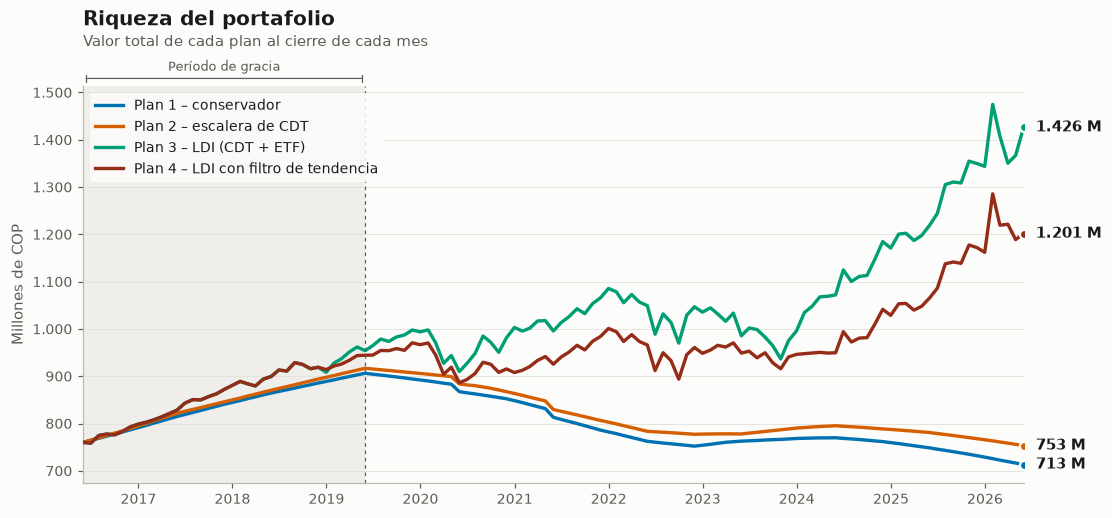

In [4]:
fig, ax_w = new_axes(
    "Riqueza del portafolio", "Millones de COP", "Valor total de cada plan al cierre de cada mes"
)
for plan, df in results.items():
    wealth = df["wealth_cop"] / 1e6
    ax_w.plot(df["date"], wealth, color=COLORS[plan], lw=2.2, label=PLANS[plan], zorder=3)
    # Final value at the right end of each line
    ax_w.plot(
        df["date"].iloc[-1], wealth.iloc[-1], "o", color=COLORS[plan], ms=6, mec=SURFACE, mew=1.5, zorder=4
    )
    ax_w.annotate(
        f"{es_number(wealth.iloc[-1])} M",
        (df["date"].iloc[-1], wealth.iloc[-1]),
        xytext=(8, 0),
        textcoords="offset points",
        va="center",
        color=TEXT,
        fontweight="bold",
        annotation_clip=False,
    )
ax_w.legend(loc="upper left", frameon=True, facecolor=SURFACE, edgecolor="none", framealpha=0.85)
plt.show()

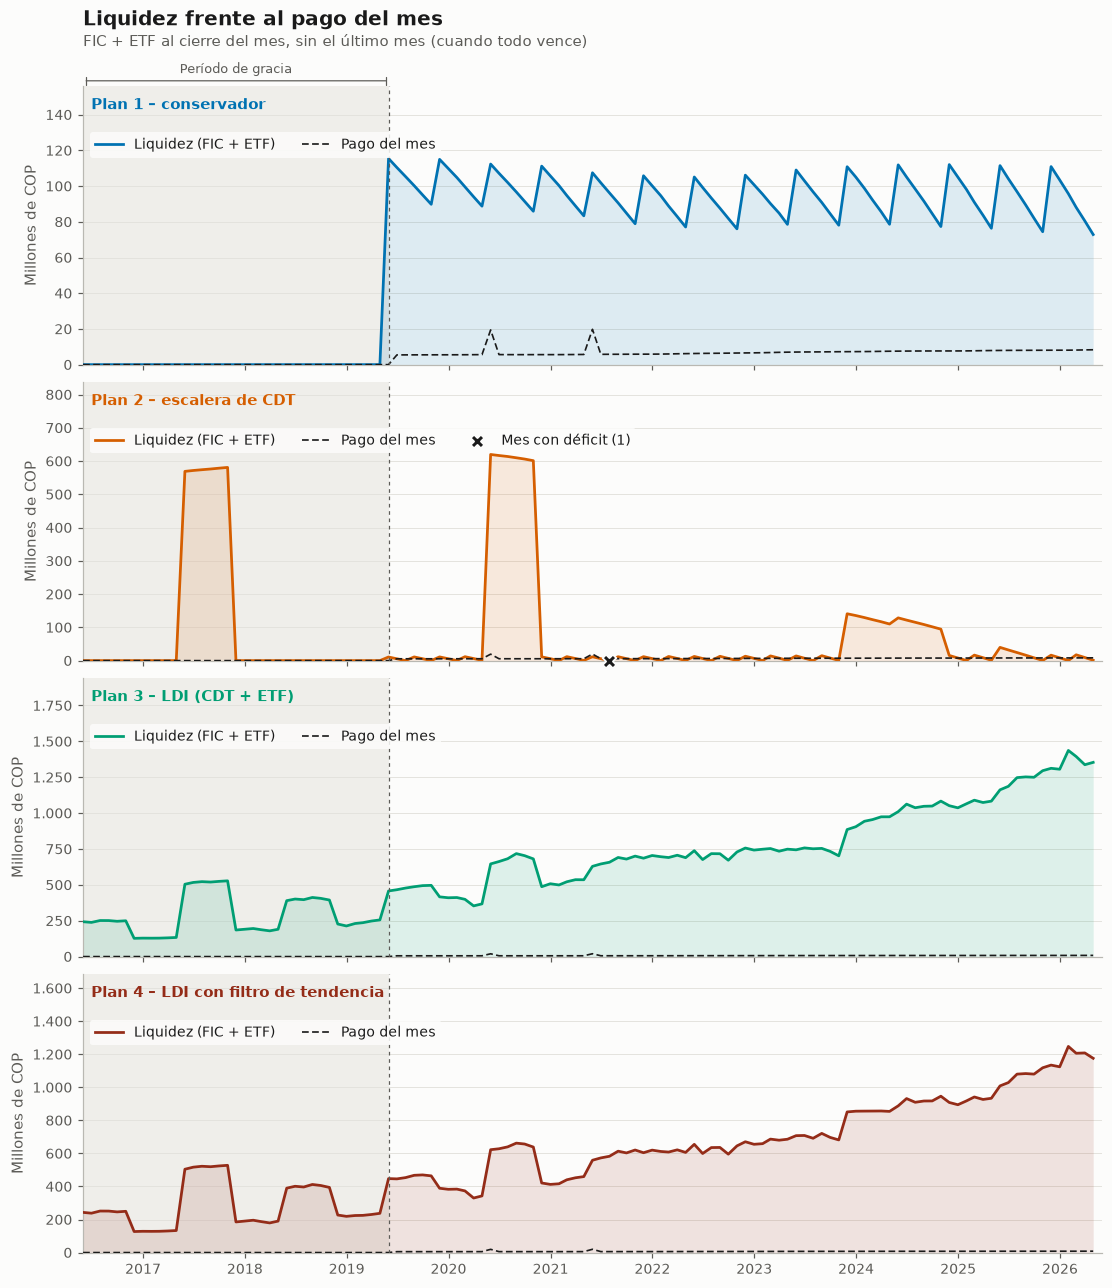

In [5]:
# Liquidez: FIC + ETF de cada plan (el ETF se vende si el FIC no alcanza) frente al pago del mes.
# Un panel por plan, cada uno con su escala: la liquidez del plan 3 aplastaría a la de los otros dos.
# Sin el último mes: en el mes H vencen todos los CDT y la escala no dejaría ver el resto.
last_month = bt["horizon_months"]
payments = results["conservative"].query("month < @last_month")
fig, axes = plt.subplots(len(results), 1, figsize=(10, 2.9 * len(results)), sharex=True, layout="constrained")
for ax, (plan, df) in zip(axes, results.items(), strict=True):
    style_axes(ax, "Millones de COP")
    df = df[df["month"] < last_month]
    liquid = (df["fic_cop"] + df["etf_cop"]) / 1e6
    ax.fill_between(df["date"], liquid, color=COLORS[plan], alpha=0.12, lw=0, zorder=1)
    ax.plot(df["date"], liquid, color=COLORS[plan], lw=1.8, label="Liquidez (FIC + ETF)", zorder=3)
    ax.plot(
        payments["date"],
        payments["payment_cop"] / 1e6,
        color=TEXT,
        lw=1.1,
        ls=(0, (4, 2)),
        label="Pago del mes",
        zorder=3,
    )
    short = df["shortfall_cop"] > 0
    ax.scatter(
        df["date"][short],
        liquid[short],
        s=80,
        marker="X",
        color=TEXT,
        edgecolor=SURFACE,
        linewidth=1.2,
        zorder=5,
        clip_on=False,
        label=f"Mes con déficit ({short.sum()})" if short.any() else None,
    )
    ax.set_ylim(bottom=0)
    ax.set_ylim(top=liquid.max() * 1.35)  # headroom for the plan name and the legend
    ax.text(0.008, 0.96, PLANS[plan], transform=ax.transAxes, va="top", fontweight="bold", color=COLORS[plan])
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(0, 0.86),
        ncols=3,
        frameon=True,
        facecolor=SURFACE,
        edgecolor="none",
        framealpha=0.85,
    )
add_header(
    axes[0],
    "Liquidez frente al pago del mes",
    "FIC + ETF al cierre del mes, sin el último mes (cuando todo vence)",
)
plt.show()

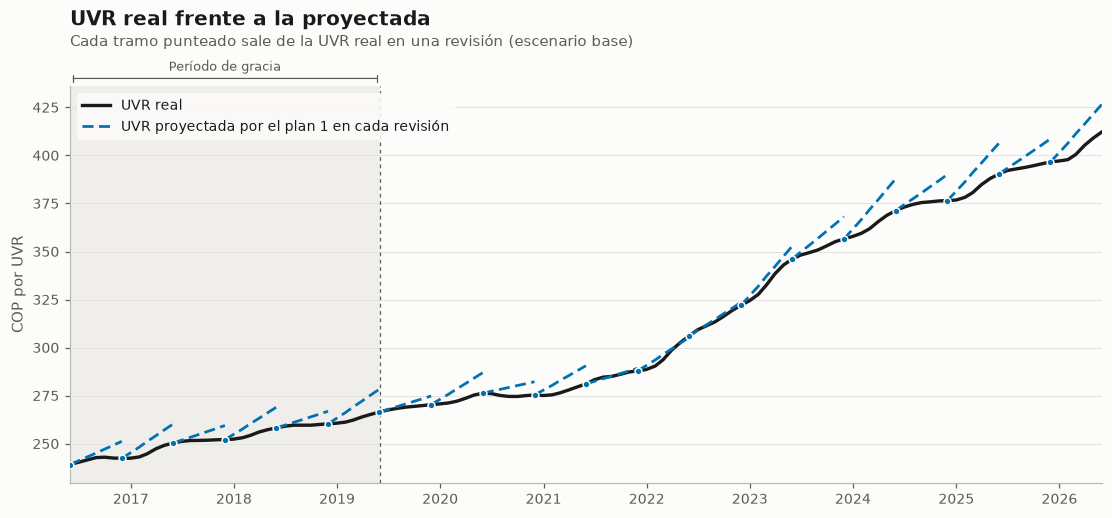

In [6]:
# UVR real en tinta; las proyecciones del plan 1 en su color, dibujadas encima (zorder mayor)
fig, ax_u = new_axes(
    "UVR real frente a la proyectada",
    "COP por UVR",
    f"Cada tramo punteado sale de la UVR real en una revisión (escenario {SCENARIO_NAMES[scenario]})",
)
ax_u.plot(dates, uvr_real.values, color=TEXT, lw=2.2, label="UVR real", zorder=2)
for i, p in enumerate(projections):
    label = "UVR proyectada por el plan 1 en cada revisión" if i == 0 else None
    ax_u.plot(p.index, p.values, color=COLORS["conservative"], lw=1.8, ls=(0, (4, 2)), label=label, zorder=3)
    ax_u.plot(
        p.index[0], p.values[0], "o", color=COLORS["conservative"], ms=4.5, mec=SURFACE, mew=1, zorder=4
    )
ax_u.legend(loc="upper left", frameon=True, facecolor=SURFACE, edgecolor="none", framealpha=0.85)
plt.show()

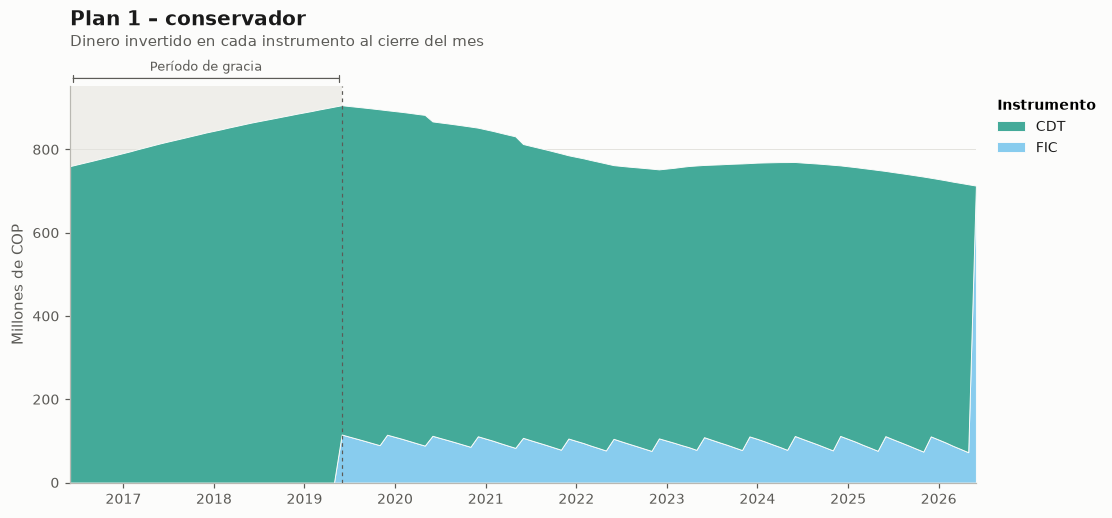

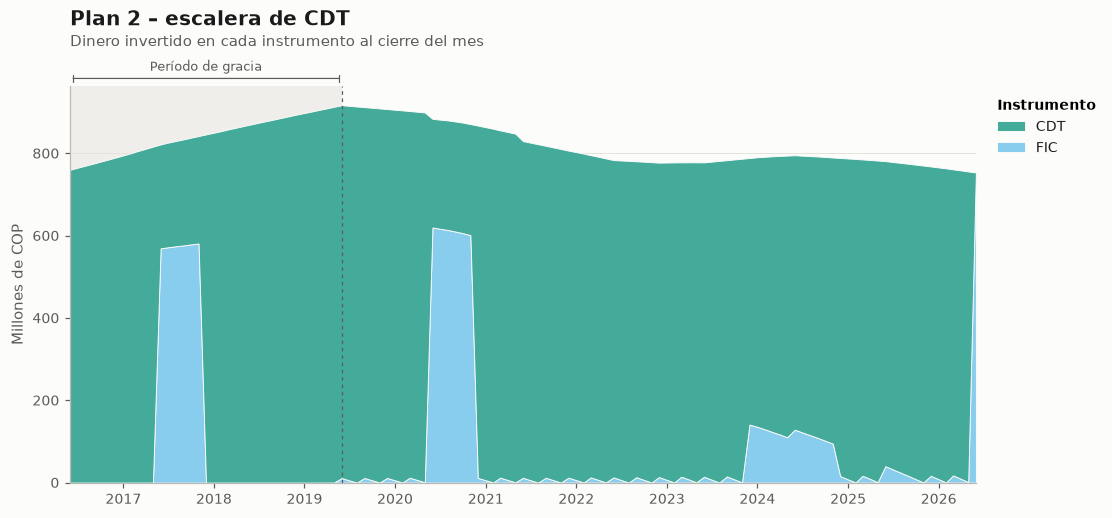

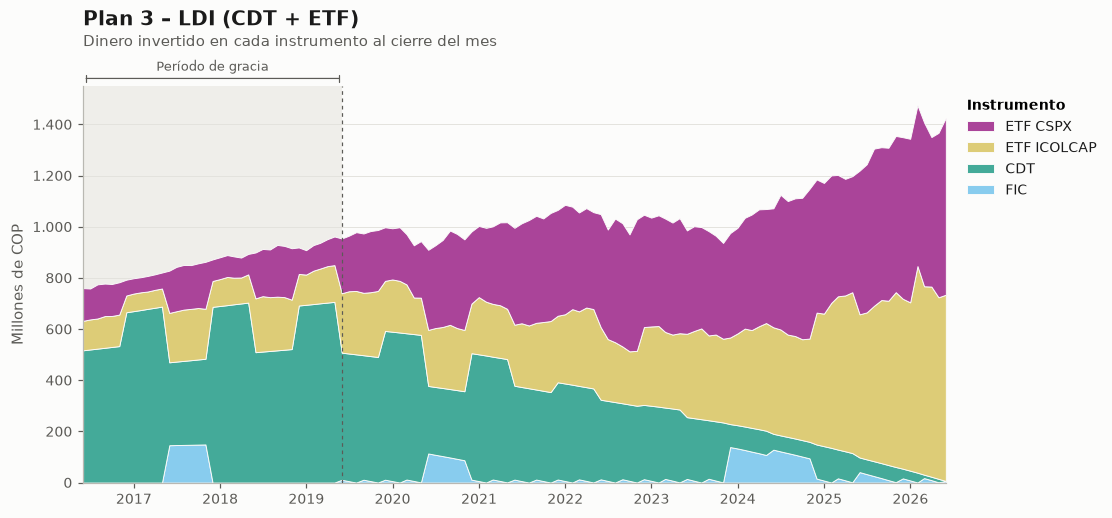

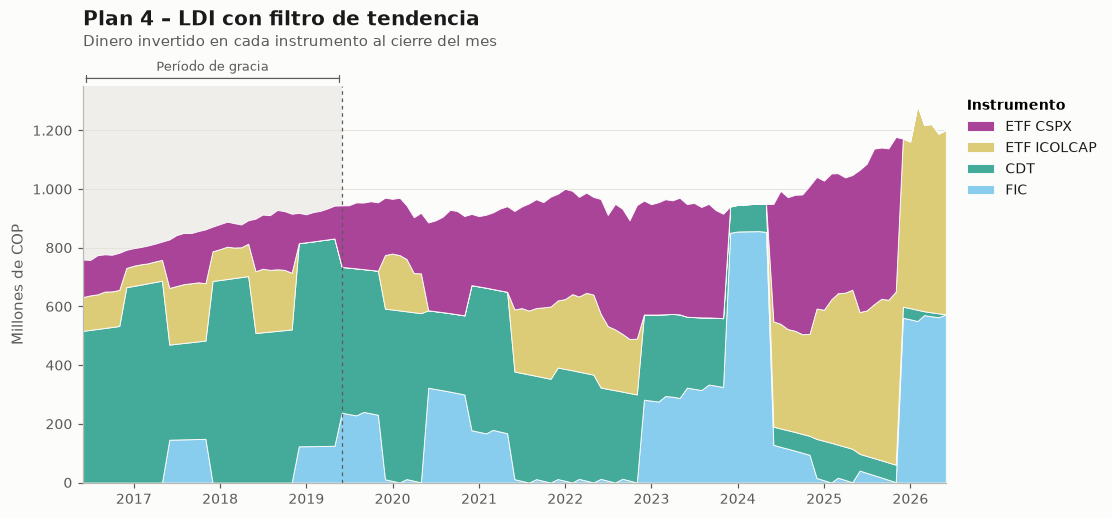

In [7]:
# Dinero en cada instrumento al cierre del mes, apilado (el total es la riqueza del plan)
INSTRUMENTS = {
    "fic_cop": ("FIC", "#88CCEE"),
    "cdt_cop": ("CDT", "#44AA99"),
    "icolcap_cop": ("ETF ICOLCAP", "#DDCC77"),
    "cspx_cop": ("ETF CSPX", "#AA4499"),
}


def stacked(ax, df, series: dict):
    """Stacked areas with a thin light border between layers; legend outside, in the order of the stack."""
    ax.stackplot(
        df["date"],
        list(series.values()),
        colors=[INSTRUMENTS[col][1] for col in series],
        labels=[INSTRUMENTS[col][0] for col in series],
        edgecolor=SURFACE,
        linewidth=0.6,
        zorder=2,
    )
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(
        handles[::-1],
        labels[::-1],
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        title="Instrumento",
        title_fontproperties={"weight": "bold", "size": 9},
        alignment="left",
    )


for plan, df in results.items():
    used = [col for col in INSTRUMENTS if df[col].abs().max() > 0]  # solo los instrumentos que el plan usa
    fig, ax = new_axes(
        PLANS[plan], "Millones de COP", "Dinero invertido en cada instrumento al cierre del mes"
    )
    stacked(ax, df, {col: df[col] / 1e6 for col in used})
    ax.set_ylim(bottom=0)
    plt.show()

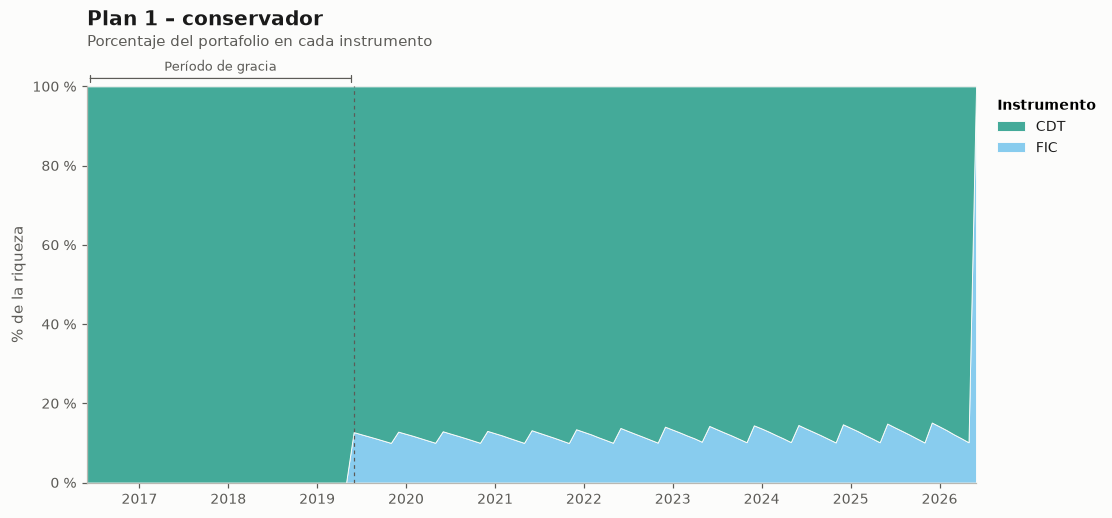

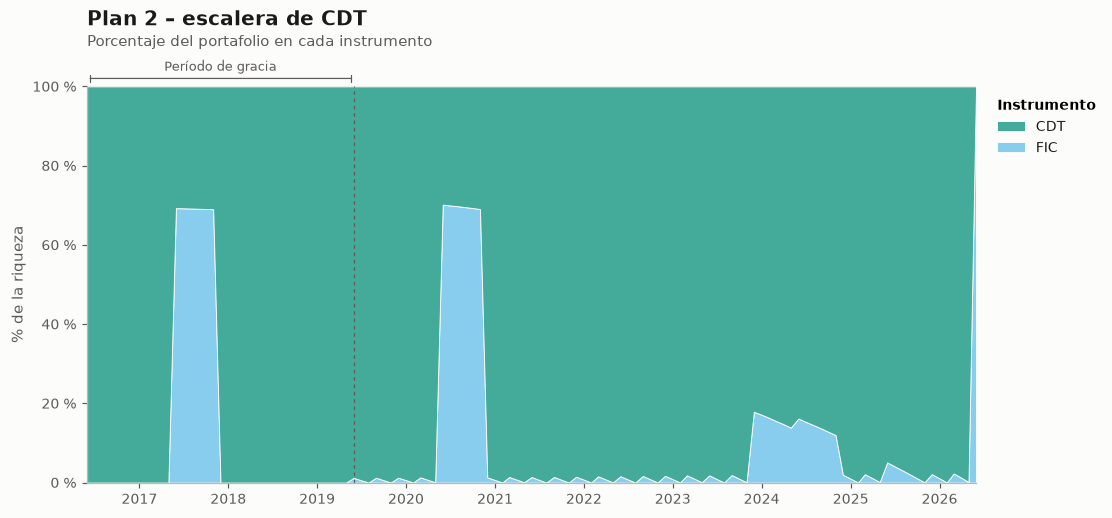

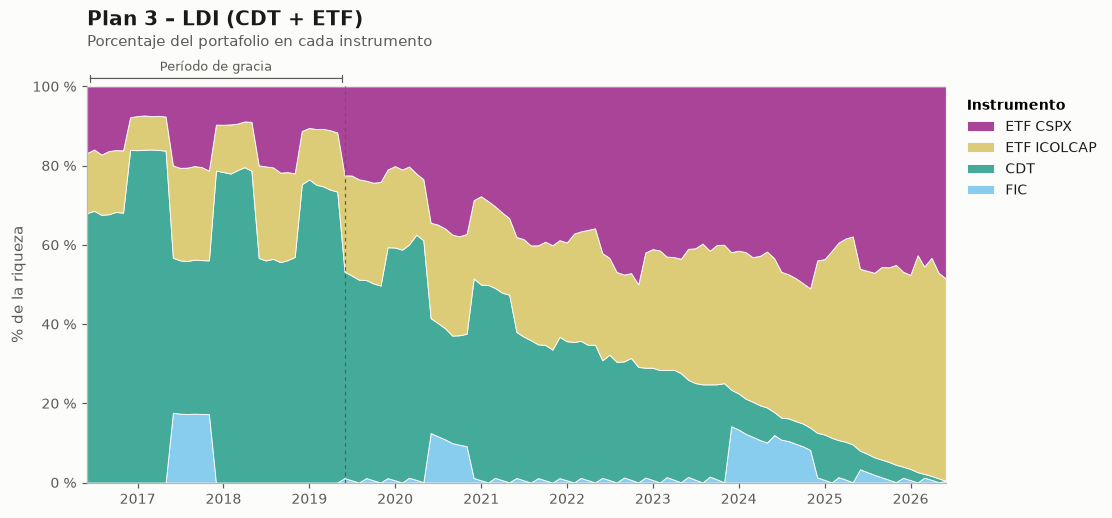

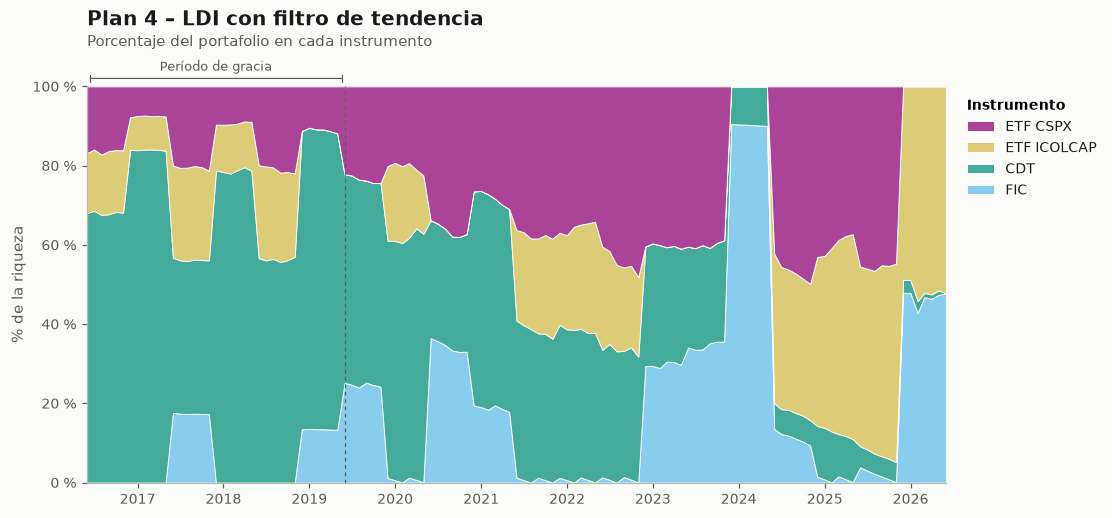

In [8]:
# Lo mismo en porcentaje: la suma de los instrumentos es 100 % en cada mes
for plan, df in results.items():
    used = [col for col in INSTRUMENTS if df[col].abs().max() > 0]
    share = df[used].div(df[used].sum(axis=1), axis=0) * 100
    fig, ax = new_axes(
        PLANS[plan], "% de la riqueza", "Porcentaje del portafolio en cada instrumento", shade_grace=False
    )
    stacked(ax, df, {col: share[col] for col in used})
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.0f} %"))
    plt.show()

## Prueba de estrés

La prueba repite el backtest de los planes 2, 3 y 4 cambiando solo los precios de los ETF desde t0 (tasas, UVR, FIC y pagos son los observados):

- **ETF −50 % y ETF −80 %:** cada ETF conserva sus rendimientos mensuales observados menos una constante, y termina en 50 % o 20 % de su precio de oct-2016.
- **Caída −60 %:** precios observados hasta oct-2019, caída de 60 % en nov-2019 y precios planos después.

El detalle está en `docs/reglas_de_inversion.md`.

In [9]:
import numpy as np

if CASE:
    print("La prueba de estrés no se recalcula para esta corrida (empieza en may-2016, no en oct-2016).")
else:
    # Riqueza neta final de los planes 2, 3 y 4 en cada escenario (results/stress_summary.csv)
    SCENARIOS = {"real": "Real", "etf_-50%": "ETF −50 %", "etf_-80%": "ETF −80 %", "crash_-60%": "Caída −60 %"}
    stress = pd.read_csv(RESULTS_DIR / "stress_summary.csv")
    net = stress.pivot(index="scenario", columns="plan", values="final_wealth_net_cop").loc[list(SCENARIOS)] / 1e6
    net = net[[plan for plan in PLANS if plan in net.columns]]  # plan order and colors as in the other charts

    fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
    x = np.arange(len(net))
    width = 0.8 / len(net.columns)
    for i, plan in enumerate(net.columns):
        offset = (i - (len(net.columns) - 1) / 2) * width
        bars = ax.bar(
            x + offset,
            net[plan],
            width,
            color=COLORS[plan],
            edgecolor=SURFACE,  # 2 px gap between neighboring bars
            linewidth=2,
            label=PLANS[plan],
            zorder=3,
        )
        ax.bar_label(bars, labels=[es_number(v, 1) for v in net[plan]], padding=3, fontsize=8.5, color=TEXT)
    ax.set_xticks(x, [SCENARIOS[s] for s in net.index])
    ax.tick_params(axis="x", length=0)
    ax.set_ylabel("Millones de COP")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: es_number(y)))
    ax.set_ylim(0, net.to_numpy().max() * 1.12)
    ax.set_title("Prueba de estrés: riqueza neta final", loc="left", pad=26)
    ax.annotate(
        "Planes 2, 3 y 4 cuando cambian solo los precios de los ETF",
        (0, 1),
        xycoords="axes fraction",
        xytext=(0, 10),
        textcoords="offset points",
        color=TEXT_2,
        va="bottom",
    )
    ax.legend(loc="upper right", frameon=True, facecolor=SURFACE, edgecolor="none", framealpha=0.85)
    plt.show()

    # Table view of the same values (millions of COP)
    display(net.round(1).rename(index=SCENARIOS, columns=PLANS))

La prueba de estrés no se recalcula para esta corrida (empieza en may-2016, no en oct-2016).
